# 10.C.2. Оптимальное согласование

**Сквозной вопрос блока:** прогнозы уровней не складываются — как сделать их согласованными и при этом точнее?

В 10.C.1 мы увидели, что любой метод согласования записывается как $\tilde y = S\,G\,\hat y$, а BU и TD —
крайние случаи, выбрасывающие часть базовых прогнозов. Здесь ищем $G$, которая использует **все** прогнозы.
Есть два принципиально разных способа её найти:

- **MinT** (Minimum Trace): базовые прогнозы — зашумлённые *измерения* согласованной истины.
  Ищем согласованный вектор, ближайший к измерениям с учётом их надёжности. Нужна модель ошибок (матрица $W$).
- **ERM** (Empirical Risk Minimization): базовые прогнозы — *признаки*. Учим $G$ по истории как обычную
  регрессию «факт ~ базовые прогнозы». Модель ошибок не нужна, зато нужно много данных.

В этом ноутбуке:
- MinT через игрушечный пример total = a + b: согласование как объединение измерений;
- общая формула, выбор $W$ (OLS, WLS struct, WLS var, MinT cov / shrink) и почему MinT «оптимальный»;
- ERM: что меняется, если отказаться от несмещённости и учить $G$ на данных;
- сравнение всех методов по уровням на TourismSmall;
- отрицательные согласованные прогнозы и `nonnegative=True`;
- пара слов о согласовании интервалов и временных иерархиях.

In [1]:
import warnings

warnings.filterwarnings('ignore')

from functools import partial

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from hierarchicalforecast.core import HierarchicalReconciliation
from hierarchicalforecast.evaluation import evaluate
from hierarchicalforecast.methods import ERM, BottomUp, MinTrace, TopDown
from hierarchicalforecast.utils import aggregate
from statsforecast import StatsForecast
from statsforecast.models import AutoETS
from utilsforecast.losses import mase

plt.rcParams['figure.figsize'] = (12, 4)

H = 8  # горизонт: 8 кварталов

## 0. Данные и базовые прогнозы

TourismSmall: 56 нижних рядов `штат-цель-зона`, иерархия total → цель → штат×цель → city/noncity (89 рядов),
36 кварталов. Последние 8 кварталов — тест, базовая модель — AutoETS по каждому ряду.

In [2]:
wide = pd.read_csv('../data/hierarchical/TourismSmall/data.csv', index_col=0, parse_dates=True)
bottom_cols = [c for c in wide.columns if c.count('-') == 2]

bottom = wide[bottom_cols].rename_axis('ds').reset_index().melt('ds', var_name='series', value_name='y')
bottom[['state', 'purpose', 'area']] = bottom['series'].str.split('-', expand=True)
bottom['total'] = 'total'

spec = [
    ['total'],
    ['total', 'purpose'],
    ['total', 'purpose', 'state'],
    ['total', 'purpose', 'state', 'area'],
]
Y_df, S_df, tags = aggregate(bottom[['ds', 'y', 'total', 'purpose', 'state', 'area']], spec)

S = S_df.drop(columns='unique_id').to_numpy()
n_series, n_bottom = S.shape
ids = S_df['unique_id'].to_numpy()


def to_matrix(df, col):
    """Long-формат → матрица (ряды в порядке S × моменты времени)."""
    return df.pivot(index='unique_id', columns='ds', values=col).loc[ids].to_numpy()


cutoff = Y_df['ds'].sort_values().unique()[-H - 1]
Y_train = Y_df[Y_df['ds'] <= cutoff]
Y_test = Y_df[Y_df['ds'] > cutoff]

In [3]:
sf = StatsForecast(models=[AutoETS(season_length=4)], freq='QE', n_jobs=1)
Y_hat = sf.forecast(df=Y_train, h=H, fitted=True)
Y_fitted = sf.forecast_fitted_values()

Y_hat_mat = to_matrix(Y_hat, 'AutoETS')  # 89 × 8
residuals = to_matrix(Y_fitted, 'y') - to_matrix(Y_fitted, 'AutoETS')  # 89 × 28 — ошибки на обучении

print(f'S: {S.shape}, базовые прогнозы: {Y_hat_mat.shape}, остатки: {residuals.shape}')

S: (89, 56), базовые прогнозы: (89, 8), остатки: (89, 28)


## 1. MinT: согласование как объединение измерений

### Игрушечный пример

Иерархия total = a + b, базовые прогнозы: total = 10, a = 4, b = 5. Они несогласованы: 4 + 5 = 9 ≠ 10.

Посмотрим на это так: у нас есть **два независимых измерения** одной и той же величины — будущего total:

- прямой прогноз total: $\hat y_{total} = 10$;
- сумма прогнозов нижних рядов: $\hat y_a + \hat y_b = 9$.

Как объединить два измерения? Классический ответ (два термометра с разной точностью): взвесить
**обратно пропорционально дисперсиям ошибок**. Если дисперсии ошибок прогнозов $w_{total}, w_a, w_b$
и ошибки независимы, то у суммы $\hat y_a + \hat y_b$ дисперсия $w_a + w_b$, и

$$\tilde y_{total} = \frac{\hat y_{total}/w_{total} + (\hat y_a + \hat y_b)/(w_a + w_b)}{1/w_{total} + 1/(w_a + w_b)}.$$

Дальше разницу между новым total и суммой $\hat y_a + \hat y_b$ надо раздать нижним рядам —
пропорционально их дисперсиям: кто шумнее, тот и двигается сильнее.

**Все дисперсии равны ($W = I$, метод OLS).** Прямой прогноз вдвое точнее суммы (дисперсия 1 против 2):
$\tilde y_{total} = (10 + 9/2)/(1 + 1/2) = 9.67$. Сумма нижних должна вырасти с 9 до 9.67 — поровну
на a и b, по $+1/3$. Итого: total $-1/3$, a $+1/3$, b $+1/3$ — расхождение 1 поделилось поровну на три ряда.

In [4]:
S_toy = np.array([[1, 1], [1, 0], [0, 1]])
y_hat_toy = np.array([10.0, 4.0, 5.0])

G_ols_toy = np.linalg.inv(S_toy.T @ S_toy) @ S_toy.T
y_tilde_toy = S_toy @ G_ols_toy @ y_hat_toy

print('согласованный прогноз (total, a, b):', y_tilde_toy.round(3))
print('total = a + b:', np.isclose(y_tilde_toy[0], y_tilde_toy[1] + y_tilde_toy[2]))

P = S_toy @ G_ols_toy
print('P = SG — проектор (P·P = P):', np.allclose(P @ P, P))
print('поправка ортогональна плоскости (Sᵀ(ŷ − ỹ) = 0):', np.allclose(S_toy.T @ (y_hat_toy - y_tilde_toy), 0))

согласованный прогноз (total, a, b): [9.667 4.333 5.333]
total = a + b: True
P = SG — проектор (P·P = P): True
поправка ортогональна плоскости (Sᵀ(ŷ − ỹ) = 0): True


**Total шумнее ($W = \mathrm{diag}(2, 1, 1)$, метод WLS struct).** Если считать, что ошибка total — это
сумма двух независимых нижних ошибок, то у прямого прогноза total та же дисперсия 2, что и у суммы.
Измерения равноценны, берём простое среднее: $\tilde y_{total} = (10 + 9)/2 = 9.5$, a и b получают
по $+0.25$. Total теперь сдвинулся сильнее (на $-0.5$), потому что мы ему меньше доверяем.

Геометрически это проекция $\hat y$ на плоскость согласованных векторов $\{S b\}$.
OLS — ортогональная проекция (перпендикуляр); при $W \ne I$ проекция «косая»: вдоль направления,
по которому измерения наименее надёжны.

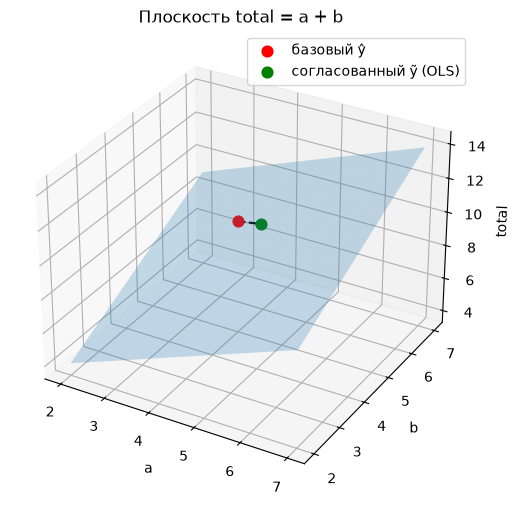

In [5]:
a_grid, b_grid = np.meshgrid(np.linspace(2, 7, 10), np.linspace(2, 7, 10))

fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(projection='3d')
ax.plot_surface(a_grid, b_grid, a_grid + b_grid, alpha=0.25)
ax.scatter(*y_hat_toy[[1, 2, 0]], color='red', s=60, label='базовый ŷ')
ax.scatter(*y_tilde_toy[[1, 2, 0]], color='green', s=60, label='согласованный ỹ (OLS)')
ax.plot(*np.c_[y_hat_toy, y_tilde_toy][[1, 2, 0]], 'k--')
ax.set_xlabel('a')
ax.set_ylabel('b')
ax.set_zlabel('total')
ax.set_title('Плоскость total = a + b')
ax.legend()
plt.show()

### Общий случай

В большой иерархии «измерений» каждого агрегата много (прямой прогноз, сумма детей, сумма внуков, …),
а ошибки могут быть коррелированы. Обобщение той же идеи — **обобщённый МНК**: ищем нижний уровень $b$,
для которого согласованный вектор $S b$ ближе всего к базовым прогнозам в метрике, учитывающей
надёжность измерений:

$$\tilde b = \arg\min_b\, (\hat y - S b)^\top W^{-1} (\hat y - S b)
\quad\Rightarrow\quad
G = (S^\top W^{-1} S)^{-1} S^\top W^{-1}, \qquad \tilde y = S G \hat y.$$

Здесь $W$ — ковариация ошибок базовых прогнозов: на диагонали — насколько шумен каждый ряд,
вне диагонали — насколько ошибки рядов «ходят вместе». $W^{-1}$ в критерии означает: отклоняться от
шумного прогноза дёшево, от точного — дорого.

Ту же формулу можно переписать в форме, где виден смысл поправки. Разобьём $S = \begin{pmatrix} A \\ I\end{pmatrix}$
(верхние строки — агрегаты $A$, нижние — единичная матрица) и введём $U^\top = [\,I \mid -A\,]$. Тогда
условие согласованности — это однородная система $U^\top y = 0$, а $U^\top \hat y$ — вектор
несогласованностей (для каждого агрегата: прогноз агрегата минус сумма прогнозов нижних рядов). Отсюда

$$\tilde y = \hat y - W U (U^\top W U)^{-1} U^\top \hat y.$$

**Поправка пропорциональна несогласованности и раздаётся рядам пропорционально $W$.** Согласованный
прогноз ($U^\top \hat y = 0$) не меняется вовсе. В игрушке $U^\top \hat y = 10 - 4 - 5 = 1$, и при
диагональной $W$ поправки равны $\mp w_i / (w_{total} + w_a + w_b)$ — ровно $-1/3, +1/3, +1/3$ для OLS
и $-0.5, +0.25, +0.25$ для WLS struct. hierarchicalforecast считает именно в этой форме: обращать
приходится матрицу $U^\top W U$ размера «число агрегатов» (33), а не всю $W$ (89). Обе записи дают
один и тот же результат — это одна и та же косая проекция, просто посчитанная разными способами.

Проверим формулу на TourismSmall для OLS ($W = I$).

In [6]:
def reconcile_manual(W):
    """G = (Sᵀ W⁻¹ S)⁻¹ Sᵀ W⁻¹ и согласованный прогноз S·G·ŷ."""
    W_inv = np.linalg.inv(W)
    G = np.linalg.solve(S.T @ W_inv @ S, S.T @ W_inv)
    return G, S @ G @ Y_hat_mat


G_ols, Y_ols_manual = reconcile_manual(np.eye(n_series))

Y_ols_lib = HierarchicalReconciliation([MinTrace(method='ols')]).reconcile(
    Y_hat_df=Y_hat[['unique_id', 'ds', 'AutoETS']], S_df=S_df, tags=tags
)
print('OLS руками = библиотека:', np.allclose(Y_ols_manual, to_matrix(Y_ols_lib, 'AutoETS/MinTrace_method-ols')))

OLS руками = библиотека: True


**Слабое место OLS.** При $W = I$ все ряды получают поправки одного порядка *в абсолютных единицах*.
Total (десятки тысяч ночей) и `nt-oth-noncity` (десятки ночей) двигаются одинаково — для маленького ряда
это огромная относительная ошибка, вплоть до отрицательного прогноза. Нужны веса.

### Выбор $W$ — это допущение об ошибках

Все варианты MinTrace — одна и та же формула, отличается только то, что мы предполагаем об ошибках
базовых прогнозов:

| метод | $W$ | допущение | оценивается по данным |
|---|---|---|---|
| OLS | $I$ | все ряды одинаково шумные, ошибки независимы | ничего |
| WLS struct | $\mathrm{diag}(S\mathbf{1})$ | нижние ошибки независимы и одинаковы, ошибка агрегата ~ сумма ошибок детей | ничего: у нас веса 1 / 2 / 14 / 56 |
| WLS var | $\mathrm{diag}(\hat\sigma^2_i)$ | ошибки независимы, но шум у рядов разный | 89 дисперсий |
| MinT cov | $\hat W$ — выборочная ковариация остатков | — (берём как есть) | 89·90/2 ≈ 4000 параметров |
| MinT shrink | $\lambda\,\mathrm{diag}(\hat W) + (1-\lambda)\,\hat W$ | корреляции есть, но оценены грубо | ≈ 4000 параметров + сжатие |

WLS struct не требует истории вообще — только структуру иерархии; WLS var учитывает масштаб рядов,
но игнорирует, что ошибки, например, всех рядов `hol` связаны общей сезонностью. Полная ковариация
учитывает и это — если её удаётся оценить.

In [7]:
W_struct = np.diag(S.sum(axis=1))
W_var = np.diag((residuals**2).mean(axis=1))

_, Y_struct_manual = reconcile_manual(W_struct)
_, Y_var_manual = reconcile_manual(W_var)

Y_wls_lib = HierarchicalReconciliation([MinTrace(method='wls_struct'), MinTrace(method='wls_var')]).reconcile(
    Y_hat_df=Y_hat[['unique_id', 'ds', 'AutoETS']],
    Y_df=Y_fitted[['unique_id', 'ds', 'y', 'AutoETS']],
    S_df=S_df,
    tags=tags,
)
print(
    'WLS struct руками = библиотека:',
    np.allclose(Y_struct_manual, to_matrix(Y_wls_lib, 'AutoETS/MinTrace_method-wls_struct')),
)
print(
    'WLS var руками = библиотека:   ',
    np.allclose(Y_var_manual, to_matrix(Y_wls_lib, 'AutoETS/MinTrace_method-wls_var'), rtol=1e-4),
)

WLS struct руками = библиотека: True
WLS var руками = библиотека:    True


 True
WLS var руками = библиотека:    True


### MinT при коротких рядах

Для полной ковариации нужно оценить ≈ 4000 параметров по 28 векторам остатков. Выборочная ковариация
из $T$ центрированных векторов имеет ранг не выше $T - 1 = 27$ — она вырождена. Даже в форме
с ограничениями нужна обратимая $U^\top W U$ размера 33 × 33, а её ранг тоже не больше 27.

In [8]:
W_cov = np.cov(residuals)

mint_shrink = MinTrace(method='mint_shrink')
mint_shrink.fit(
    S=S, y_hat=Y_hat_mat, y_insample=to_matrix(Y_fitted, 'y'), y_hat_insample=to_matrix(Y_fitted, 'AutoETS')
)
W_shrink = mint_shrink.W

print(f'размер W: {W_cov.shape}, наблюдений: {residuals.shape[1]}')
print(f'ранг выборочной ковариации: {np.linalg.matrix_rank(W_cov)}')
print(f'число обусловленности: mint_cov {np.linalg.cond(W_cov):.1e}, mint_shrink {np.linalg.cond(W_shrink):.1e}')

размер W: (89, 89), наблюдений: 28
ранг выборочной ковариации: 27
число обусловленности: mint_cov 3.9e+20, mint_shrink 1.5e+03


Формально `mint_cov` считается (численно система решается), но веса опираются на вырожденную,
плохо оценённую матрицу — ниже увидим, к чему это приводит.

**Shrinkage** (Schäfer–Strimmer) — компромисс между «диагональ» (WLS var: мало параметров, но корреляции
выброшены) и «полная матрица» (всё учтено, но оценки шумные). Внедиагональные элементы стягиваются к нулю
с коэффициентом $\lambda$, который подбирается по данным: чем шумнее выборочные корреляции, тем
сильнее сжатие. Матрица становится невырожденной — это стандартный выбор на практике.

### Почему «Minimum Trace» и почему «оптимальное»

Пусть базовые прогнозы **несмещённые**, а $W_h$ — ковариация их ошибок на горизонте $h$.
Если $G$ сохраняет согласованные векторы ($GS = I$), то ошибка согласованного прогноза — это
$\tilde e = S G \hat e$, и её ковариация $S G W_h G^\top S^\top$. Сумма дисперсий ошибок всех рядов —
след (trace) этой матрицы.

**Теорема (Wickramasuriya, Athanasopoulos, Hyndman, 2019).** Среди всех $G$ с $GS = I$ след
минимален при $G = (S^\top W_h^{-1} S)^{-1} S^\top W_h^{-1}$ — то есть при той самой формуле обобщённого МНК.

Это многомерная версия «двух термометров»: среди несмещённых линейных комбинаций измерений минимальную
дисперсию даёт взвешивание обратно пропорционально дисперсиям (с учётом корреляций). Более того,
при известной $W_h$ согласованный прогноз **не хуже базового ни для одного ряда** — дополнительные
измерения не могут навредить, если правильно знаешь их точность.

Два честных «но»:
- $W_h$ для $h > 1$ неизвестна. На практике берут остатки на обучении (прогноз на шаг вперёд)
  и предполагают $W_h = k_h W_1$; множитель $k_h$ в формуле для $G$ сокращается.
- Оптимальность гарантирована только при точной $W$ и несмещённых базовых прогнозах. С оценкой $W$
  по 28 точкам — см. `mint_cov` ниже.

**Несмещённость.** Если $E\hat y = S\beta$, то $E\tilde y = SGS\beta$, и согласованный прогноз несмещён
при $SGS = S$ (эквивалентно $GS = I$). Для формулы обобщённого МНК это выполнено при любой $W$.
BU тоже проходит (это предельный случай: дисперсия ошибок агрегатов → ∞, им совсем не доверяем),
а TD — нет.

In [9]:
train_mat = to_matrix(Y_train, 'y')
p_avg = (train_mat[-n_bottom:] / train_mat[0]).mean(axis=1)

G_matrices = {
    'BU': np.hstack([np.zeros((n_bottom, n_series - n_bottom)), np.eye(n_bottom)]),
    'TD avg_prop': np.hstack([p_avg[:, None], np.zeros((n_bottom, n_series - 1))]),
    'OLS': G_ols,
    'WLS struct': reconcile_manual(W_struct)[0],
    'WLS var': reconcile_manual(W_var)[0],
    'MinT shrink': reconcile_manual(W_shrink)[0],
}
for name, G in G_matrices.items():
    print(f'{name:12s} SGS = S: {np.allclose(S @ G @ S, S)}')

BU           SGS = S: True
TD avg_prop  SGS = S: False
OLS          SGS = S: True
WLS struct   SGS = S: True
WLS var      SGS = S: True
MinT shrink  SGS = S: True


TD нарушает условие: даже идеальные несмещённые нижние прогнозы он заменяет долями от total.

## 2. ERM: учим $G$ по данным

MinT опирается на два допущения: базовые прогнозы несмещённые, а их ошибки описываются матрицей $W$,
которую мы умеем оценить. Ben Taieb и Koo (2019) предложили отказаться от обоих и спросить напрямую:
**какая $G$ дала бы наименьшую ошибку согласованного прогноза на истории?**

$$G^{*} = \arg\min_G \sum_{t \in \text{valid}} \lVert y_t - S G \hat y_t \rVert^2.$$

Ограничения $GS = I$ нет. Это обычная линейная регрессия: каждый нижний ряд предсказываем по всем
89 базовым прогнозам, коэффициенты — строка $G$. Решение в явном виде: $G^{*} = B\,\hat Y^{+}$,
где $B$ — факт нижних рядов на валидации, $\hat Y$ — базовые прогнозы на тех же моментах.

**Разница в одной картинке — направление регрессии:**

| | MinT | ERM |
|---|---|---|
| модель | $\hat y = S b + \varepsilon$: прогнозы — шумные измерения истины | $b \approx G \hat y$: прогнозы — признаки |
| что регрессируем | прогнозы на структуру $S$ | факт на прогнозы |
| допущения | несмещённость, известная $W$ | никаких, кроме линейности |
| что оцениваем | $W$ (от 0 до ≈ 4000 параметров) | вся $G$: 56 × 89 = 4984 параметра |
| что нужно | остатки на обучении | валидационное окно с прогнозами на $h$ шагов |
| сильная сторона | работает на коротких рядах (OLS, WLS) | исправляет систематическое смещение базовых моделей |

Если, скажем, ETS систематически завышает прогноз ряда на 10%, MinT честно перенесёт это смещение
в согласованный прогноз (он предполагает, что смещения нет). ERM выучит коэффициент ≈ 0.9 и исправит.
Цена — переобучение: параметров тысячи, наблюдений — столько, сколько точек в валидации.

Поэтому есть регуляризованные варианты:
- `reg` — lasso на элементы $G$ (большинство обнуляется);
- `reg_bu` — lasso на $G - G_{BU}$: по умолчанию остаёмся bottom-up и отходим от него, только если данные
  уверенно на это указывают. При очень большом $\lambda$ получается ровно BU.

**Деталь реализации hierarchicalforecast:** в статье $G$ учат на валидационном окне с настоящими прогнозами
на $h$ шагов. Библиотека вместо этого берёт последние $h$ точек **прогнозов на обучении** (на шаг вперёд).
У нас это 8 моментов × 89 рядов = 712 чисел на 4984 параметра. Коэффициент `lambda_reg` задаётся
в абсолютных единицах, а ряды у нас в тысячах ночей, так что значение по умолчанию `1e-2` почти не регуляризует.

## 3. Сравнение всех методов по уровням

In [10]:
reconcilers = [
    BottomUp(),
    TopDown(method='forecast_proportions'),
    MinTrace(method='ols'),
    MinTrace(method='wls_struct'),
    MinTrace(method='wls_var'),
    MinTrace(method='mint_cov'),
    MinTrace(method='mint_shrink'),
    ERM(method='closed'),
    ERM(method='reg_bu'),
]
names = {
    'AutoETS': 'Base',
    'AutoETS/BottomUp': 'BU',
    'AutoETS/TopDown_method-forecast_proportions': 'TD fcst_prop',
    'AutoETS/MinTrace_method-ols': 'OLS',
    'AutoETS/MinTrace_method-wls_struct': 'WLS struct',
    'AutoETS/MinTrace_method-wls_var': 'WLS var',
    'AutoETS/MinTrace_method-mint_cov': 'MinT cov',
    'AutoETS/MinTrace_method-mint_shrink': 'MinT shrink',
    'AutoETS/ERM_method-closed_lambda_reg-0.01': 'ERM closed',
    'AutoETS/ERM_method-reg_bu_lambda_reg-0.01': 'ERM reg_bu',
}

hrec = HierarchicalReconciliation(reconcilers=reconcilers)
Y_rec = hrec.reconcile(
    Y_hat_df=Y_hat[['unique_id', 'ds', 'AutoETS']],
    Y_df=Y_fitted[['unique_id', 'ds', 'y', 'AutoETS']],
    S_df=S_df,
    tags=tags,
).rename(columns=names)

Y_eval = Y_rec.merge(Y_test, on=['unique_id', 'ds'])
evaluation = evaluate(Y_eval, metrics=[partial(mase, seasonality=4)], tags=tags, train_df=Y_train)

table = evaluation.drop(columns='metric').set_index('level')
table.style.format('{:.3f}').highlight_min(axis=1, color='lightgreen')

,Base,BU,TD fcst_prop,OLS,WLS struct,WLS var,MinT cov,MinT shrink,ERM closed,ERM reg_bu
level,,,,,,,,,,
total,1.567,1.436,1.567,1.597,1.611,1.613,225.467,1.617,3.153,67.816
total/purpose,1.173,1.248,1.112,1.130,1.235,1.237,192.381,1.235,2.147,39.468
total/purpose/state,0.951,0.880,0.888,0.887,0.892,0.890,375.514,0.892,1.988,89.419
total/purpose/state/area,0.855,0.855,0.852,0.844,0.851,0.856,340.725,0.855,2.071,169.604
Overall,0.908,0.887,0.883,0.879,0.890,0.893,343.708,0.892,2.060,137.384


### Наблюдения

- **`mint_cov` ломается:** MASE в сотнях на всех уровнях. Ковариация 89 × 89 по 28 точкам вырождена
  (число обусловленности ~10²⁰), веса бессмысленны — и ниже мы увидим сотни отрицательных прогнозов.
  Shrinkage полностью убирает проблему.
- **ERM ломается ещё сильнее** — по той же причине, только хуже: оценить нужно не 4000 элементов $W$,
  а 4984 элемента $G$, причём по 8 моментам времени. `closed` даёт решение с минимальной нормой среди
  бесконечного множества идеально подогнанных; `reg_bu` с почти нулевым $\lambda$ — то же переобучение.
  ERM — инструмент для длинных рядов с честным валидационным окном, а не для 36 кварталов.
- Остальные согласованные методы в целом (Overall) не хуже базового прогноза: согласованность не стоит точности,
  а обычно даже немного её добавляет (OLS 0.879, TD fcst_prop 0.883, BU 0.887 против 0.908 у Base).
- Лучшие по уровням разные: на total — BU, на уровне целей — TD `forecast_proportions` и OLS,
  на нижнем уровне — OLS.
- OLS / WLS / MinT shrink отличаются на 1–2% — это уровень шума для одного окна из 8 кварталов.
  Преимущество MinT (минимальная дисперсия) — теоретическое и проявляется при надёжной оценке ковариации,
  а у нас всего 28 векторов остатков.

Общий урок: чем больше параметров оценивает метод (OLS → WLS → MinT → ERM), тем больше данных ему нужно.
На коротких рядах простые допущения о $W$ выигрывают у гибких методов.

## 4. Отрицательные согласованные прогнозы

OLS и MinT перераспределяют расхождение между рядами — маленький нижний ряд может получить отрицательную
поправку больше собственного прогноза. Для ночей в отелях это бессмысленно. (Пара отрицательных значений
есть уже у базового ETS.)

In [11]:
negatives = (Y_rec[list(names.values())] < 0).sum()
negatives[negatives > 0] if negatives.any() else negatives

Base              2
BU                2
TD fcst_prop      2
OLS               2
WLS struct        1
MinT cov        338
ERM closed       25
ERM reg_bu      414
dtype: int64

`nonnegative=True` решает тот же взвешенный МНК, но с ограничением $\tilde b \ge 0$ на нижние ряды
(агрегаты тогда неотрицательны автоматически). Это задача квадратичного программирования: решение уже
не линейно по $\hat y$, и гарантии несмещённости и оптимальности из раздела 1 формально теряются —
платим ими за осмысленные значения.

In [12]:
Y_nonneg = HierarchicalReconciliation([MinTrace(method='ols'), MinTrace(method='ols', nonnegative=True)]).reconcile(
    Y_hat_df=Y_hat[['unique_id', 'ds', 'AutoETS']], S_df=S_df, tags=tags
)

ols_cols = ['AutoETS/MinTrace_method-ols', 'AutoETS/MinTrace_method-ols_nonnegative-True']
print('Отрицательных прогнозов:')
print((Y_nonneg[ols_cols] < 0).sum())

Отрицательных прогнозов:
AutoETS/MinTrace_method-ols                     2
AutoETS/MinTrace_method-ols_nonnegative-True    0
dtype: int64


## 5. Замечание: согласование интервалов

Всё выше — про точечные прогнозы. Интервалы согласованного прогноза не получаются бесплатно: нельзя просто
согласовать границы базовых интервалов (сумма квантилей — не квантиль суммы). Нужно согласовывать
**распределение** целиком, а для этого — знать совместную структуру ошибок всех рядов на горизонте $h$,
ту самую $W_h$, которую мы и для точечных прогнозов оцениваем грубо. Это отдельная задача со своими
методами (гауссовское согласование, бутстреп, ранговые перестановки, конформные интервалы), и покрытие
в ней надо отдельно проверять по уровням иерархии. Обзор — в Panagiotelis et al. (2023).

## 6. За рамками: временные и кросс-временные иерархии

- **Временная иерархия:** один ряд на разных частотах (месяц → квартал → год) — тоже сумма, тоже $y = Sb$.
  В hierarchicalforecast её строит `aggregate_temporal`, согласование — те же `BottomUp` / `MinTrace`
  (`reconcile(..., temporal=True)`). Годовой прогноз становится равен сумме месячных.
- **Кросс-временное согласование:** одновременно по структуре (регионы) и по времени (частоты).
  Матрица $S$ — произведение Кронекера структурной и временной; `get_cross_temporal_tags` собирает теги.
- Идея та же, что и с ADIDA для прерывистого спроса: прогноз на агрегированной частоте точнее,
  а согласование передаёт эту точность обратно на исходную частоту.

## Итог

Все методы — $\tilde y = S G \hat y$. Различаются тем, как ищут $G$:

| Метод | Как получается $G$ | Что нужно | Когда брать |
|---|---|---|---|
| OLS | проекция, $W = I$ | только $S$ | быстрый старт, нет остатков |
| WLS struct | проекция, $W$ = число нижних рядов | только $S$ | нет надёжных остатков, разный масштаб уровней |
| WLS var | проекция, $W$ = дисперсии остатков | in-sample прогнозы | короткие ряды, много рядов |
| MinT cov | проекция, полная ковариация | наблюдений ≫ рядов | почти никогда на практике |
| MinT shrink | проекция, сжатая ковариация | in-sample прогнозы | выбор по умолчанию |
| ERM | регрессия факта на прогнозы, без $GS = I$ | длинное валидационное окно | много данных, смещённые базовые модели |

- **MinT-семейство:** прогнозы — измерения истины, объединяем их с весами по надёжности. Несмещённо
  ($SGS = S$) и оптимально при верной $W$; выбор $W$ — это допущение об ошибках.
- **ERM:** $G$ учится напрямую, может исправить смещение базовых моделей, но требует на порядки больше данных.
- Для неотрицательных величин — `nonnegative=True`.
- Интервалы — отдельная задача, согласование точечных прогнозов её не решает.

**Литература**
- Hyndman, Ahmed, Athanasopoulos, Shang (2011). *Optimal combination forecasts for hierarchical time series.* CSDA.
- Wickramasuriya, Athanasopoulos, Hyndman (2019). *Optimal forecast reconciliation for hierarchical and grouped
  time series through trace minimization.* JASA.
- Ben Taieb, Koo (2019). *Regularized regression for hierarchical forecasting without unbiasedness conditions.* KDD.
- Schäfer, Strimmer (2005). *A shrinkage approach to large-scale covariance matrix estimation.* SAGMB.
- Panagiotelis, Gamakumara, Athanasopoulos, Hyndman (2023). *Probabilistic forecast reconciliation.* EJOR.
- Hyndman, Athanasopoulos. *Forecasting: Principles and Practice* (3rd ed.), гл. 11.